In [ ]:
import pandas as pd
import numpy as np


In [14]:
df =pd.read_csv(r'C:\Users\hp\Documents\Depi\cardio_train.csv', sep=';')
df.head()      #show the first 5 rows


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
#Check data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [16]:
# Display statistical summary of the numerical columns
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [17]:
# Count missing or null values in each column
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [18]:
# Check for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [ ]:
# View unique values and their counts for a specific categorical column 
df['gender'].value_counts()

gender
1    45530
2    24470
Name: count, dtype: int64

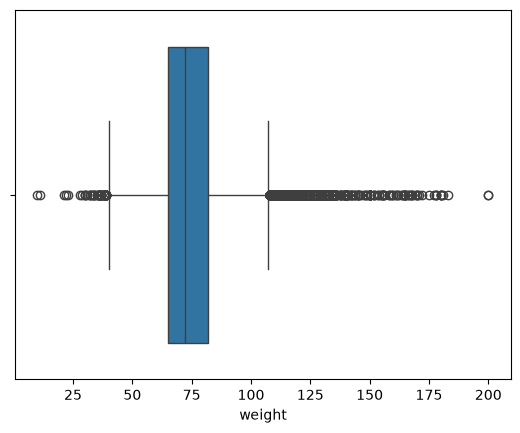

In [20]:
# Visualize outliers using a boxplot for numerical features like height or weight
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['weight'])
plt.show()

In [21]:
# Check and convert data types if needed
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

In [22]:
# Check rows where diastolic pressure is greater than systolic pressure
invalid_bp = df[df['ap_lo'] > df['ap_hi']]
invalid_bp.shape[0]  # Number of logical errors

1234

In [27]:
# Convert age from days to years
df['age'] = (df['age'] / 365).astype(int)

In [28]:
# Remove unrealistic blood pressure and physical measurements outliers
df = df[
    (df['ap_hi'] >= 80) & (df['ap_hi'] <= 250) &
    (df['ap_lo'] >= 50) & (df['ap_lo'] <= 150) &
    (df['height'] >= 130) & (df['height'] <= 220) &
    (df['weight'] >= 40) & (df['weight'] <= 200)
]

In [29]:
df.shape

(68585, 13)

In [30]:
# Check the distribution of the target variable (cardio)
df['cardio'].value_counts()

cardio
0    34636
1    33949
Name: count, dtype: int64

In [31]:
# Save the cleaned dataset to a new CSV file
df.to_csv(r'C:\Users\hp\Documents\Depi\cardio_cleaned.csv', index=False)
print("Dataset saved successfully!")

Dataset saved successfully!
